# Retail Demand Forecasting

## Can last week’s sales predict next week’s sales?

I’ll start with one product at one store and forecast seven days of sales. For each day, my prediction is the number of units sold on the same weekday one week earlier.

In [ ]:
from pathlib import Path
import pandas as pd 

## Check the data files

The sales file records daily units sold for each product at each store. The calendar file maps day labels such as `d_1` to dates. I check that both files are available before loading the data.

In [9]:
data_dir = Path("data/raw")
print("Data folder:", data_dir.resolve())
print("Sales file:", (data_dir / "sales_train_validation.csv").is_file())
print("Calendar file:", (data_dir / "calendar.csv").is_file())

Data folder: /home/ravi/retail-demand-forecasting/data/raw
Sales file: True
Calendar file: True


## Can last week’s sales predict next week’s sales?

In [ ]:
sales_preview = pd.read_csv(data_dir / "sales_train_validation.csv", nrows=5)
sales_preview[["item_id", "store_id", "d_1", "d_2", "d_3"]]

,item_id,store_id,d_1,d_2,d_3
0,HOBBIES_1_001,CA_1,0,0,0
1,HOBBIES_1_002,CA_1,0,0,0
2,HOBBIES_1_003,CA_1,0,0,0
3,HOBBIES_1_004,CA_1,0,0,0
4,HOBBIES_1_005,CA_1,0,0,0


## Test a weekly baseline

For product `HOBBIES_1_001` at store `CA_1`, I use the final seven days as a test week. Each forecast uses sales from exactly seven days earlier. The table pairs each prediction with the actual units sold that day.

In [11]:
product = sales_preview.iloc[0]
daily_sales = product.filter(regex=r"^d_\d+$").astype(int)

forecast = pd.DataFrame({
    "forecast_units": daily_sales.shift(7),
    "actual_units": daily_sales,
}).tail(7)

forecast

,forecast_units,actual_units
d_1907,0.0,1
d_1908,0.0,1
d_1909,0.0,1
d_1910,1.0,3
d_1911,1.0,0
d_1912,3.0,1
d_1913,0.0,1


## How far off was the forecast?

I’ll measure the gap between predicted and actual sales for each of the seven days. An overestimate of 2 units and an underestimate of 2 units both count as a 2-unit error. The average of these gaps is the mean absolute error (MAE).

In [12]:
forecast["absolute_error"] = (
    forecast["forecast_units"] - forecast["actual_units"]
).abs()

mae = forecast["absolute_error"].mean()

display(forecast)
f"Mean absolute error: {mae:.2f} units per day"

,forecast_units,actual_units,absolute_error
d_1907,0.0,1,1.0
d_1908,0.0,1,1.0
d_1909,0.0,1,1.0
d_1910,1.0,3,2.0
d_1911,1.0,0,1.0
d_1912,3.0,1,2.0
d_1913,0.0,1,1.0


'Mean absolute error: 1.29 units per day'

## Compare the forecast with actual sales

This chart shows the final seven days for product `HOBBIES_1_001` at store `CA_1`. Each forecast uses the units sold on the same weekday one week earlier.

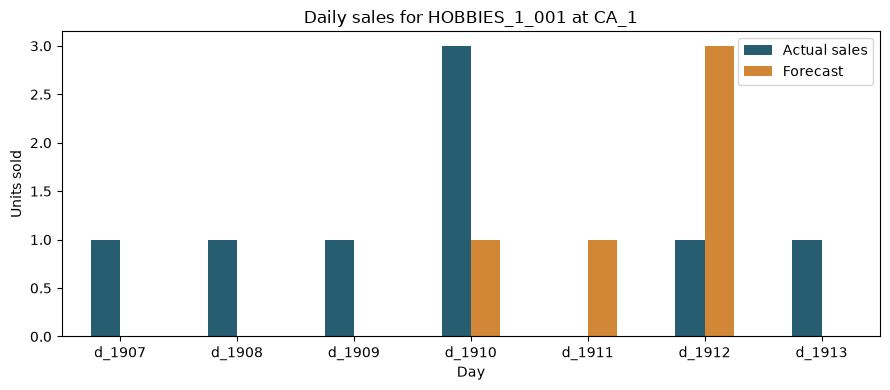

In [16]:
ax = forecast[["actual_units", "forecast_units"]].plot.bar(
    figsize=(9, 4),
    color=["#275D70", "#D18735"],
    rot=0,
    title="Daily sales for HOBBIES_1_001 at CA_1",
    xlabel="Day",
    ylabel="Units sold",
)
ax.legend(["Actual sales", "Forecast"])
ax.figure.tight_layout()

## Does the weekly baseline hold up over four weeks?

For HOBBIES_1_001 at store CA_1, I’ll evaluate the final four weeks separately. Each daily forecast uses sales from seven days earlier. I’ll compare the mean absolute error (MAE) across the four weeks to see how much the daily error varies.

In [17]:
backtest = pd.DataFrame({
    "actual_units": daily_sales,
    "forecast_units": daily_sales.shift(7),
}).tail(28).copy()

backtest["week"] = ["Week 1", "Week 2", "Week 3", "Week 4"] * 1 if False else (
    ["Week 1"] * 7 + ["Week 2"] * 7 + ["Week 3"] * 7 + ["Week 4"] * 7
)
backtest["absolute_error"] = (
    backtest["actual_units"] - backtest["forecast_units"]
).abs()

weekly_results = backtest.groupby("week").agg(
    actual_units_sold=("actual_units", "sum"),
    forecast_units=("forecast_units", "sum"),
    mae_per_day=("absolute_error", "mean"),
)

weekly_results.round(2)

,actual_units_sold,forecast_units,mae_per_day
week,,,
Week 1,2,8.0,0.86
Week 2,12,2.0,1.71
Week 3,5,12.0,1.86
Week 4,8,5.0,1.29


## Does averaging four weeks improve the forecast?

I’ll compare two forecasts for the same product over the same 28 test days. The first uses sales from the previous week. The second averages sales from the four previous occurrences of the same weekday. I’ll compare their mean absolute error in units per day.

In [18]:
same_weekday_sales = pd.DataFrame({
    "one_week_ago": daily_sales.shift(7),
    "two_weeks_ago": daily_sales.shift(14),
    "three_weeks_ago": daily_sales.shift(21),
    "four_weeks_ago": daily_sales.shift(28),
})

predictions = pd.DataFrame({
    "Last week": backtest["forecast_units"],
    "Four-week average": same_weekday_sales.mean(axis=1).loc[backtest.index],
})

errors = predictions.sub(backtest["actual_units"], axis=0).abs()
errors.mean().sort_values().round(2).to_frame("MAE (units per day)")

,MAE (units per day)
Four-week average,1.00
Last week,1.43


## Compare forecast accuracy across five products

I’ll test both methods on five products from store CA_1 over the same 28 days. For each product, I’ll compare the daily MAE from using last week’s sales with the MAE from averaging the previous four matching weekdays.

In [19]:
results = []

for _, product_row in sales_preview.iterrows():
    units = product_row.filter(regex=r"^d_\d+$").astype(int)
    actual = units.tail(28)

    last_week = units.shift(7).tail(28)
    four_week_avg = (
        units.shift(7) + units.shift(14) + units.shift(21) + units.shift(28)
    ).tail(28) / 4

    results.append({
        "item_id": product_row["item_id"],
        "last_week_mae": (actual - last_week).abs().mean(),
        "four_week_avg_mae": (actual - four_week_avg).abs().mean(),
    })

product_scores = pd.DataFrame(results).set_index("item_id")
product_scores.round(2)

,last_week_mae,four_week_avg_mae
item_id,,
HOBBIES_1_001,1.43,1.00
HOBBIES_1_002,0.25,0.29
HOBBIES_1_003,0.64,0.65
HOBBIES_1_004,2.46,1.59
HOBBIES_1_005,1.50,1.16


## Which method worked better for more products?

For each of the five products at CA_1, I’ll count which method had the lower daily MAE over the final 28 days. Equal scores count as a tie.

In [20]:
last_week = product_scores["last_week_mae"]
four_week = product_scores["four_week_avg_mae"]

comparison = pd.Series({
    "Four-week average had lower error": (four_week < last_week).sum(),
    "Last week had lower error": (last_week < four_week).sum(),
    "Both had equal error": (four_week == last_week).sum(),
}, name="Products")

comparison.to_frame()

,Products
Four-week average had lower error,3
Last week had lower error,2
Both had equal error,0


## Which method had the lower average error?

At store CA_1, the four-week average had a lower MAE for 3 of the 5 products over the final 28 days. Last week’s sales gave a lower MAE for the other 2. There were no ties.

To measure the size of the errors across all five products, I’ll average their MAEs, giving each product equal weight.

In [21]:
overall_mae = product_scores[["last_week_mae", "four_week_avg_mae"]].mean()
overall_mae.sort_values().to_frame("MAE per product per day").round(3)

,MAE per product per day
four_week_avg_mae,0.939
last_week_mae,1.257


## How much did the forecast error change?

I’ll use last week’s sales as the baseline and measure the percentage reduction in MAE from using the four-week average. This comparison covers five products at store CA_1 over the final 28 days.

In [22]:
baseline_mae = overall_mae["last_week_mae"]
four_week_mae = overall_mae["four_week_avg_mae"]

reduction_pct = (baseline_mae - four_week_mae) / baseline_mae * 100

pd.DataFrame({
    "Last-week MAE": [baseline_mae],
    "Four-week MAE": [four_week_mae],
    "Error reduction (%)": [reduction_pct],
}).round(3)

,Last-week MAE,Four-week MAE,Error reduction (%)
0,1.257,0.939,25.284


## Do the results hold up the following week?

I’ll forecast days 1914–1920 for the same five products at CA_1, using sales available through day 1913. Then I’ll compare both forecasts with the recorded sales and calculate the MAE across all 35 product-day predictions.

In [23]:
keys = ["store_id", "item_id"]
history = sales_preview.set_index(keys)
actual_sales = pd.read_csv(
    data_dir / "sales_train_evaluation.csv", nrows=5
).set_index(keys).loc[history.index]

errors = []

for day in range(1914, 1921):
    last_week = history[f"d_{day - 7}"]
    previous_days = [f"d_{day - lag}" for lag in (7, 14, 21, 28)]
    four_week_avg = history[previous_days].mean(axis=1)
    actual = actual_sales[f"d_{day}"]

    errors.append(pd.DataFrame({
        "Last week": (actual - last_week).abs(),
        "Four-week average": (actual - four_week_avg).abs(),
    }))

next_week_mae = pd.concat(errors).mean()
next_week_mae.sort_values().to_frame("Next-week MAE").round(3)

,Next-week MAE
Four-week average,0.829
Last week,1.229


## Did the same method perform better the following week?

I’ll compare the MAE of both methods across two periods for the same five products at CA_1. In each column, the lower value means a smaller average error per product per day.

In [24]:
earlier_mae = overall_mae.rename(index={
    "last_week_mae": "Last week",
    "four_week_avg_mae": "Four-week average",
})

period_comparison = pd.DataFrame({
    "Earlier 28 days": earlier_mae,
    "Following 7 days": next_week_mae,
})

period_comparison.round(3)

,Earlier 28 days,Following 7 days
Last week,1.257,1.229
Four-week average,0.939,0.829


## Which products sold more than forecast?

I’ll compare the four-week average forecast with actual sales for days 1914–1920. For each product, I’ll subtract the weekly forecast from weekly sales. A positive gap means the product sold more units than forecast. A negative gap means it sold fewer.


In [25]:
daily_forecasts = {}

for day in range(1914, 1921):
    previous_days = [f"d_{day - lag}" for lag in (7, 14, 21, 28)]
    daily_forecasts[f"d_{day}"] = history[previous_days].mean(axis=1)

week_forecast = pd.DataFrame(daily_forecasts)

weekly_gap = pd.DataFrame({
    "actual_units": actual_sales[week_forecast.columns].sum(axis=1),
    "forecast_units": week_forecast.sum(axis=1),
})

weekly_gap["gap_units"] = weekly_gap["actual_units"] - weekly_gap["forecast_units"]
weekly_gap.sort_values("gap_units", ascending=False)

actual_units  forecast_units  gap_units
store_id item_id                                               
CA_1     HOBBIES_1_001            10            6.75       3.25
         HOBBIES_1_004            14           12.75       1.25
         HOBBIES_1_003             5            4.00       1.00
         HOBBIES_1_002             1            0.50       0.50
         HOBBIES_1_005            10            9.50       0.50

## Can a learned forecast beat the four-week average?

I’ll fit one linear regression per product using sales through day 1913. Each model uses sales from 7, 14, 21 and 28 days earlier. I’ll compare its daily MAE with the four-week average on days 1914–1920.

In [30]:
from sklearn.linear_model import LinearRegression

model_results = []
test_days = week_forecast.columns

for product_key, row in history.iterrows():
    sales = row.filter(regex=r"^d_\d+$").astype(float)

    features = pd.DataFrame({
        f"lag_{lag}": sales.shift(lag) for lag in (7, 14, 21, 28)
    }).dropna()

    model = LinearRegression()
    model.fit(features, sales.loc[features.index])

    # All four inputs for each test day come from day 1913 or earlier.
    test_features = pd.DataFrame({
        f"lag_{lag}": [sales[f"d_{day - lag}"] for day in range(1914, 1921)]
        for lag in (7, 14, 21, 28)
    }, index=test_days)

    prediction = pd.Series(model.predict(test_features), index=test_days).clip(lower=0)
    actual = actual_sales.loc[product_key, test_days]
    baseline = week_forecast.loc[product_key, test_days]

    model_results.append({
        "item_id": product_key[1],
        "four_week_mae": (actual - baseline).abs().mean(),
        "regression_mae": (actual - prediction).abs().mean(),
    })

model_scores = pd.DataFrame(model_results).set_index("item_id")
model_scores["mae_reduction"] = model_scores["four_week_mae"] - model_scores["regression_mae"]
model_scores.round(3)

,four_week_mae,regression_mae,mae_reduction
item_id,,,
HOBBIES_1_001,1.250,1.347,-0.097
HOBBIES_1_002,0.214,0.314,-0.100
HOBBIES_1_003,0.500,0.614,-0.114
HOBBIES_1_004,1.607,1.552,0.056
HOBBIES_1_005,0.571,0.891,-0.320


## Expand the comparison to 50 products

I’ll select 50 products from store CA_1 using a fixed random seed. Before testing the forecasts, I’ll check how many sampled products belong to each category.

In [31]:
catalog = pd.read_csv(
    data_dir / "sales_train_validation.csv",
    usecols=["store_id", "item_id", "cat_id"],
)

store_catalog = catalog.loc[catalog["store_id"] == "CA_1"]
sample_50 = store_catalog.sample(n=50, random_state=42).copy()

sample_50["cat_id"].value_counts().rename("products").to_frame()

,products
cat_id,
FOODS,24
HOUSEHOLD,19
HOBBIES,7


## Load daily sales for the selected products

I’ll read the sales file in batches and keep the rows for the 50 sampled products at store CA_1. Each row in the resulting table will represent one product, with one column per sales day.

In [32]:
selected_ids = sample_50["item_id"]
matched_rows = []

for chunk in pd.read_csv(data_dir / "sales_train_validation.csv", chunksize=500):
    matches = chunk["store_id"].eq("CA_1") & chunk["item_id"].isin(selected_ids)
    matched_rows.append(chunk.loc[matches].copy())

sales_50 = pd.concat(matched_rows).set_index("item_id")
history_50 = sales_50.filter(regex=r"^d_\d+$").loc[selected_ids]

history_50.shape

(50, 1913)

## Compare two forecasting baselines across 50 products

For each product at CA_1, I’ll compare last week’s sales with the average of the previous four matching weekdays. I’ll evaluate both methods over the final 28 days and calculate each product’s mean absolute error in units per day.


In [33]:
actual_28 = history_50.iloc[:, -28:]

last_week_28 = history_50.shift(7, axis="columns").iloc[:, -28:]

four_week_28 = (
    sum(history_50.shift(lag, axis="columns") for lag in (7, 14, 21, 28)) / 4
).iloc[:, -28:]

scores_50 = pd.DataFrame({
    "last_week_mae": (actual_28 - last_week_28).abs().mean(axis=1),
    "four_week_mae": (actual_28 - four_week_28).abs().mean(axis=1),
})

scores_50["mae_reduction"] = scores_50["last_week_mae"] - scores_50["four_week_mae"]
scores_50.sort_values("mae_reduction", ascending=False).head(5).round(3)

,last_week_mae,four_week_mae,mae_reduction
item_id,,,
FOODS_3_439,3.071,1.902,1.170
FOODS_2_181,3.964,3.000,0.964
FOODS_3_643,2.143,1.420,0.723
FOODS_2_135,2.286,1.705,0.580
FOODS_3_118,2.179,1.688,0.491


## Can linear regression beat the baselines across 50 products?

I’ll forecast the final four weeks one week at a time. Before each week, I’ll fit a regression for each product using sales from 7, 14, 21 and 28 days earlier. I’ll compare all three methods using the same 50 products, forecast dates and daily MAE.


In [34]:
from sklearn.linear_model import LinearRegression

regression_mae = {}

for item_id, units in history_50.iterrows():
    features = pd.DataFrame({
        f"lag_{lag}": units.shift(lag) for lag in (7, 14, 21, 28)
    })
    weekly_errors = []

    for start in range(len(units) - 28, len(units), 7):
        # The first 28 days lack a full set of lag values.
        train_x = features.iloc[28:start]
        train_y = units.iloc[28:start]
        test_x = features.iloc[start:start + 7]
        actual = units.iloc[start:start + 7]

        model = LinearRegression().fit(train_x, train_y)
        predicted = model.predict(test_x).clip(min=0)
        weekly_errors.append((actual - predicted).abs().mean())

    regression_mae[item_id] = sum(weekly_errors) / len(weekly_errors)

scores_50["regression_mae"] = pd.Series(regression_mae)

methods = ["last_week_mae", "four_week_mae", "regression_mae"]
scores_50[methods].mean().sort_values().to_frame("MAE per product per day").round(3)

,MAE per product per day
regression_mae,0.955
four_week_mae,0.985
last_week_mae,1.146


## Which products repeatedly sold more than forecast?

I’ll compare actual and forecast units for each product one week at a time. A positive weekly gap means sales exceeded the four-week average forecast. I’ll use SQL to find products with a positive gap in at least three of the four weeks.

In [35]:
import sqlite3

weekly_rows = []

for week in range(4):
    days = slice(week * 7, (week + 1) * 7)
    weekly_rows.append(pd.DataFrame({
        "item_id": actual_28.index,
        "week": week + 1,
        "actual_units": actual_28.iloc[:, days].sum(axis=1).to_numpy(),
        "forecast_units": four_week_28.iloc[:, days].sum(axis=1).to_numpy(),
    }))

weekly_sales = pd.concat(weekly_rows, ignore_index=True)

query = """
SELECT
    item_id,
    SUM(CASE WHEN actual_units > forecast_units THEN 1 ELSE 0 END)
        AS weeks_underforecast,
    ROUND(SUM(actual_units - forecast_units), 2) AS net_gap_units
FROM weekly_sales
GROUP BY item_id
HAVING SUM(CASE WHEN actual_units > forecast_units THEN 1 ELSE 0 END) >= 3
ORDER BY weeks_underforecast DESC, net_gap_units DESC, item_id
"""

with sqlite3.connect(":memory:") as db:
    weekly_sales.to_sql("weekly_sales", db, index=False)
    underforecasted = pd.read_sql_query(query, db)

underforecasted.head(10)

,item_id,weeks_underforecast,net_gap_units
0,HOUSEHOLD_1_375,4,5.25
1,HOUSEHOLD_1_272,3,105.50
2,FOODS_2_181,3,28.00
3,FOODS_3_439,3,21.75
4,HOBBIES_1_194,3,20.00
5,FOODS_1_052,3,16.75
6,FOODS_3_207,3,12.75
7,FOODS_3_189,3,11.75
8,FOODS_2_135,3,5.75
9,FOODS_2_121,3,3.25


## Findings from the 50-product backtest

I compared three methods at store CA_1 over four weekly forecasts. Each product and day carries equal weight in the MAE. I also checked how often weekly sales exceeded the four-week average forecast.

In [36]:
from IPython.display import Markdown

method_names = {
    "last_week_mae": "Last week's sales",
    "four_week_mae": "Four-week average",
    "regression_mae": "Linear regression",
}

ranking = scores_50[list(method_names)].mean().rename(index=method_names).sort_values()
display(ranking.to_frame("MAE per product per day").round(3))

best_methods = " and ".join(ranking.index[ranking == ranking.min()])
Markdown(
    f"**Lowest average error:** {best_methods} "
    f"({ranking.min():.3f} units per product per day).  \n"
    f"**Repeated underforecasting:** For {len(underforecasted)} of the "
    f"{len(scores_50)} products, weekly sales exceeded the four-week average "
    f"forecast in at least 3 of the 4 test weeks."
)

,MAE per product per day
Linear regression,0.955
Four-week average,0.985
Last week's sales,1.146


**Lowest average error:** Linear regression (0.955 units per product per day).  
**Repeated underforecasting:** For 14 of the 50 products, weekly sales exceeded the four-week average forecast in at least 3 of the 4 test weeks.

## Forecast error across three methods

The bars show mean absolute error for 50 products at store CA_1 over 28 days. A shorter bar means the method missed daily sales by fewer units on average.

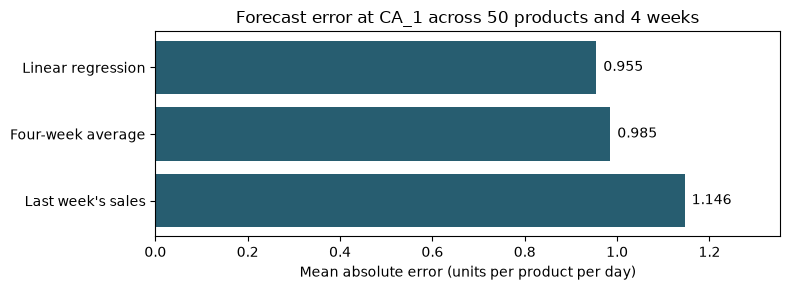

In [37]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(ranking.index, ranking.values, color="#275D70")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_xlabel("Mean absolute error (units per product per day)")
ax.set_title("Forecast error at CA_1 across 50 products and 4 weeks")
ax.margins(x=0.18)
fig.tight_layout()

chart_path = Path("figures/model_comparison.png")
chart_path.parent.mkdir(exist_ok=True)
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()

## Write the project README

I’ll use the backtest results to document the business question, evaluation method and findings. The README includes the model comparison chart and instructions for reproducing the analysis.

In [38]:
score_rows = "\n".join(
    f"| {method} | {score:.3f} |" for method, score in ranking.items()
)

readme = f"""# Retail Demand Forecasting

Can a linear regression forecast daily unit sales more accurately than repeating
last week's sales or averaging the four previous matching weekdays?

## Results

I tested {len(scores_50)} sampled products at store `CA_1` over four consecutive
7-day forecasts. Each product and day received equal weight.

| Forecast method | MAE (units per product per day) |
|---|---:|
{score_rows}

![Forecast error across three methods](figures/model_comparison.png)

## Where sales exceeded the forecast

For {len(underforecasted)} of the {len(scores_50)} products, weekly sales exceeded
the four-week average forecast in at least three of the four test weeks.
These products are candidates for a closer look during weekly planning.

## How I tested the forecasts

- Sampled products with a fixed random seed of 42.
- Compared last week's sales, a four-week same-weekday average and linear regression.
- Fitted one regression per product before each forecast week using sales from
  7, 14, 21 and 28 days earlier.
- Used SQLite to count underforecast weeks for each product.

The results cover one store and four test weeks. Recorded sales alone cannot
show whether zero sales resulted from a stockout.

## Reproduce the analysis

1. Download the [M5 Forecasting – Accuracy data](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data).
2. Place `calendar.csv`, `sales_train_validation.csv` and
   `sales_train_evaluation.csv` in `data/raw/`.
3. Install pandas, matplotlib, scikit-learn and ipykernel in a Python environment.
4. Open `01_first_forecast.ipynb` from the project root, select that environment
   as the notebook kernel and run all cells in order.
"""

readme_path = Path("README.md")
readme_path.write_text(readme, encoding="utf-8")
readme_path.resolve()

PosixPath('/home/ravi/retail-demand-forecasting/README.md')